# Machine Learning 1 - Nearest Neighbors and Decision Trees

## Lab objectives

* Classification with decision trees and random forests.
* Cross-validation and evaluation.

In [28]:
from lab_tools import CIFAR10, get_hog_image

dataset = CIFAR10('CIFAR10/')

Pre-loading training data
Pre-loading test data


# 1. Nearest Neighbor

The following example uses the Nearest Neighbor algorithm on the Histogram of Gradient decriptors in the dataset.

In [29]:
from sklearn.neighbors import KNeighborsClassifier

clf = KNeighborsClassifier(n_neighbors=3)
# i think we should set n = 3 because is exactly how many features we have in this dataset
clf.fit( dataset.train['hog'], dataset.train['labels'] )


,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


* What is the **descriptive performance** of this classifier ?
* Modify the code to estimate the **predictive performance**.
* Use cross-validation to find the best hyper-parameters for this method.

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
import numpy as np
from matplotlib import pyplot as plt


predicted = clf.predict(dataset.test['hog'])

acc = accuracy_score(dataset.test['labels'], predicted)

print(acc)

# we should use that instead use accuracy score because what we want to evaluate is the error using cross validation

scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels'], cv = 5)

print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))



0.7083333333333334
0.71 accuracy with a standard deviation of 0.01


In [31]:
from sklearn.model_selection import cross_val_score

values = np.logspace(0, 2, 20)
acc_score = []

for i in values:
    clf = KNeighborsClassifier(n_neighbors=int(i))
    scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels']).mean()
    acc_score.append(scores) # we need to use the mean because a fold impose to get not one score but multiple score



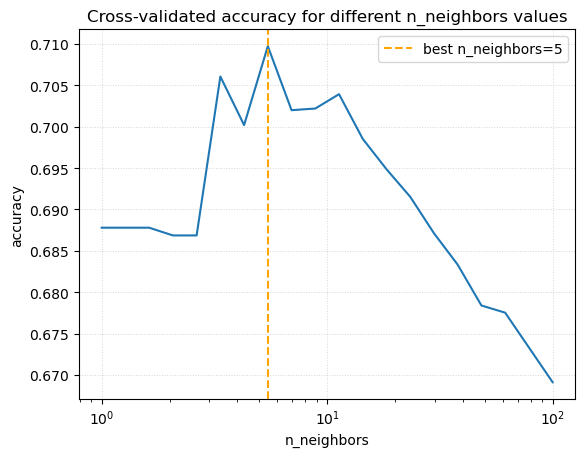

5.455594781168519


In [32]:
fig, ax = plt.subplots()
ax.plot(values, acc_score)
ax.set_xlabel("n_neighbors")
ax.set_xscale("log")
best_n_neighbors = values[np.argmax(acc_score)]
plt.ylabel("accuracy")
plt.title("Cross-validated accuracy for different n_neighbors values")
plt.axvline(best_n_neighbors, color='orange', linestyle='--', label=f'best n_neighbors={int(best_n_neighbors)}')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.5, linewidth=0.7)
plt.show()
fig.savefig("figures/cross_val_knn.pdf", bbox_inches="tight")
print(best_n_neighbors)

## 2. Decision Trees

[Decision Trees](http://scikit-learn.org/stable/modules/tree.html#tree) classify the data by splitting the feature space according to simple, single-feature rules. Scikit-learn uses the [CART](https://en.wikipedia.org/wiki/Predictive_analytics#Classification_and_regression_trees_.28CART.29) algorithm for [its implementation](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html) of the classifier. 

* **Create a simple Decision Tree classifier** using scikit-learn and train it on the HoG training set.
* Use cross-validation to find the best hyper-paramters for this method.


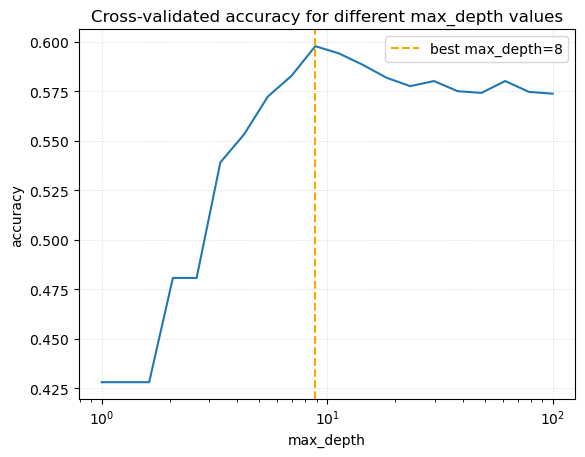

8.858667904100825


In [37]:
from sklearn import tree

from sklearn.model_selection import cross_val_score

values = np.logspace(0, 2, 20)
acc_score = []

for i in values:
    clf = tree.DecisionTreeClassifier(max_depth=int(i))
    scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels']).mean()
    acc_score.append(scores) # we need to use the mean because a fold impose to get not one score but multiple score

fig, ax = plt.subplots()
ax.plot(values, acc_score)
ax.set_xlabel("max_depth")
ax.set_xscale("log")
best_max_depth = values[np.argmax(acc_score)]
plt.ylabel("accuracy")
plt.title("Cross-validated accuracy for different max_depth values")
plt.axvline(best_max_depth, color='orange', linestyle='--', label=f'best max_depth={int(best_max_depth)}')
plt.legend()
ax.grid(True, linestyle=':', alpha=0.5, linewidth=0.7)
plt.show()
fig.savefig("figures/cross_val_dt.pdf", bbox_inches="tight")

print(best_max_depth)


# what i want to analyze is the hyper parameter max_depth, so what i've already done before is trying to use a loop and inside we will try to learn a decisiontreeclassifier
# with different max_depth values and then we are going to plot of error rate of cross validation and understand which is the minimum error rate for a specific value of max_depth



In [38]:
from sklearn import ensemble

# --- Your code here --- #
clf = ensemble.RandomForestClassifier(n_estimators=10)
clf.fit(dataset.train['hog'], dataset.train['labels'])

scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels'], cv = 5)
print("%0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

0.67 accuracy with a standard deviation of 0.01


In [39]:
from sklearn import tree

from sklearn.model_selection import cross_val_score

values = np.logspace(0, 2, 20)
acc_score = []

for i in values:
    clf = ensemble.RandomForestClassifier(n_estimators=int(i), max_depth=int(best_max_depth))
    scores = cross_val_score(clf, dataset.train['hog'], dataset.train['labels']).mean()
    acc_score.append(scores) # we need to use the mean because a fold impose to get not one score but multiple score




# what i want to analyze is the hyper parameter n_estimators, so what i've already done before is trying to use a loop and inside we will try to learn a randomforestclassifier
# with different n_estimators values and then we are going to plot of error rate of cross validation and understand which is the minimum error rate for a specific value of n_estimators



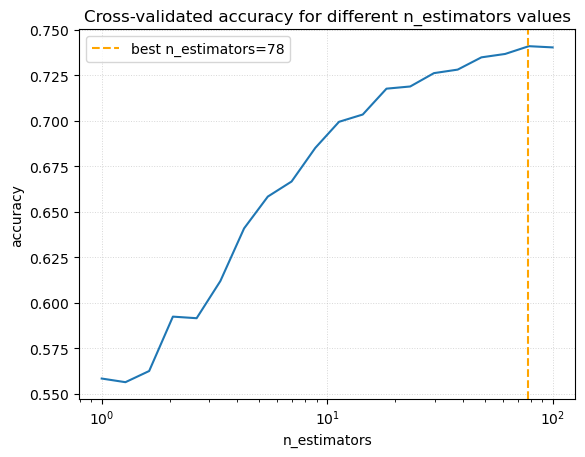

78


In [42]:
fig, ax = plt.subplots()
ax.plot(values, acc_score)
ax.set_xlabel("n_estimators")
ax.set_xscale("log")
best_n_estimators = int(values[np.argmax(acc_score)])
plt.ylabel("accuracy")
plt.title("Cross-validated accuracy for different n_estimators values")
plt.axvline(best_n_estimators, color='orange', linestyle='--', label=f'best n_estimators={best_n_estimators}')
plt.legend()
ax.grid(True, linestyle=':', alpha=0.5, linewidth=0.7)
plt.show()
fig.savefig("figures/cross_val_rf.pdf", bbox_inches="tight")
print(best_n_estimators)